In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

sns.set_style('whitegrid')
pd.set_option('display.max_columns', 50)
pd.set_option('display.width', 200)

In [2]:
df = pd.read_csv('products.csv', dtype={'unit_price': str})
df.head()

,product_id,product_name,category,sub_category,unit_price,cost_price,supplier_id,is_active,launch_date
0,P023,Footwear Item 23,Fashion,Footwear,3019.36,2515.11,S92,true,2024-06-26
1,P052,Womenswear Item 52,fashion,Womenswear,17637.28,11253.70,S001,yes,24/01/2025
2,P003,Staples Item 3 (Revised),GROCERY,Staples,9543.98,10602.65,S006,Y,2021-04-28
3,P059,NaN,NaN,Cookware,18828.5,15780.42,S006,Y,01-Nov-2020
4,P024,Footwear Item 24,FASHION,Footwear,11175.62,7441.33,S012,Y,2023-03-25


In [3]:
df.shape

(75, 9)

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 75 entries, 0 to 74
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   product_id    75 non-null     str    
 1   product_name  73 non-null     str    
 2   category      70 non-null     str    
 3   sub_category  75 non-null     str    
 4   unit_price    75 non-null     str    
 5   cost_price    75 non-null     float64
 6   supplier_id   75 non-null     str    
 7   is_active     75 non-null     str    
 8   launch_date   75 non-null     str    
dtypes: float64(1), str(8)
memory usage: 5.4 KB


In [5]:
df.isnull().sum()

product_id      0
product_name    2
category        5
sub_category    0
unit_price      0
cost_price      0
supplier_id     0
is_active       0
launch_date     0
dtype: int64

In [6]:
print(df.duplicated().sum())
print(df['product_id'].duplicated().sum())
df[df['product_id'].duplicated(keep=False)].sort_values('product_id')

0
5


,product_id,product_name,category,sub_category,unit_price,cost_price,supplier_id,is_active,launch_date
8,P001,Accessories Item 1,Electronics,Accessories,23939.11,16799.61,S014,True,31/05/2023
60,P001,Accessories Item 1 (Revised),Electronics,Accessories,10660.79,16799.61,S014,True,31/05/2023
2,P003,Staples Item 3 (Revised),GROCERY,Staples,9543.98,10602.65,S006,Y,2021-04-28
70,P003,Staples Item 3,GROCERY,Staples,-70.38,10602.65,S006,Y,2021-04-28
43,P039,Fitness Item 39,sports,Fitness,21602.68,14577.41,S011,N,12/07/2019
65,P039,Fitness Item 39 (Revised),sports,Fitness,5818.64,14577.41,S011,N,12/07/2019
20,P060,Staples Item 60,Grocery,Staples,0,18576.25,S003,yes,20/03/2019
57,P060,Staples Item 60 (Revised),Grocery,Staples,11569.57,18576.25,S003,yes,20/03/2019
6,P070,Footwear Item 70,fashion,Footwear,"₹2,902.33",2413.18,S008,no,01/01/2024
17,P070,Footwear Item 70 (Revised),fashion,Footwear,3962.52,2413.18,S008,no,01/01/2024


In [7]:
df['category'].value_counts(dropna=False)

category
Home and Kitchen    9
fashion             8
GROCERY             8
Fashion             6
Grocery             6
sports              6
NaN                 5
grocery             5
home & kitchen      4
Sports              4
electronics         4
FASHION             3
Electronics         3
Home & Kitchen      2
ELECTRONICS         1
Electornics         1
Name: count, dtype: int64

In [8]:
df.groupby('sub_category')['category'].unique()

sub_category
Accessories                           [Electronics, electronics]
Appliances                    [Home & Kitchen, Home and Kitchen]
Audio                                 [ELECTRONICS, electronics]
Beverages                            [GROCERY, grocery, Grocery]
Cookware       [nan, home & kitchen, Home and Kitchen, Home &...
Fitness                                    [sports, Sports, nan]
Footwear                             [Fashion, FASHION, fashion]
Furniture                [home & kitchen, Home and Kitchen, nan]
Menswear                                          [nan, fashion]
Mobiles                               [Electronics, Electornics]
Outdoor                                         [Sports, sports]
Snacks                                                 [GROCERY]
Staples                         [GROCERY, grocery, nan, Grocery]
Team Sports                                     [sports, Sports]
Womenswear                           [fashion, Fashion, FASHION]
Name: catego

In [9]:
df[df['unit_price'].str.contains(r'[^\d.]', na=False)][['product_id', 'unit_price']]

,product_id,unit_price
6,P070,"₹2,902.33"
22,P011,"₹1,179.68"
34,P018,"₹17,477.91"
54,P049,"₹12,393.99"
64,P058,"₹22,572.25"
70,P003,-70.38


In [10]:
df['unit_price'] = df['unit_price'].str.replace('₹', '', regex=False).str.replace(',', '', regex=False).astype(float)
df[['unit_price', 'cost_price']].describe()

,unit_price,cost_price
count,75.000000,75.000000
mean,12723.800133,10792.696133
std,7809.908342,5801.157205
min,-70.380000,828.750000
25%,5644.960000,5720.795000
50%,11932.310000,10532.220000
75%,19635.915000,15412.540000
max,27280.240000,24940.490000


In [11]:
print((df['unit_price'] <= 0).sum())
print((df['unit_price'] < df['cost_price']).sum())
df[(df['unit_price'] <= 0) | (df['unit_price'] < df['cost_price'])][['product_id', 'product_name', 'unit_price', 'cost_price']]

4
14


,product_id,product_name,unit_price,cost_price
2,P003,Staples Item 3 (Revised),9543.98,10602.65
16,P006,Furniture Item 6,2863.09,4549.93
18,P040,Footwear Item 40,0.00,1563.28
20,P060,Staples Item 60,0.00,18576.25
27,P051,Footwear Item 51,0.00,4574.85
31,P028,Appliances Item 28,7218.53,9457.58
39,P010,Accessories Item 10,1165.83,1730.66
40,P020,Beverages Item 20,3634.57,5171.78
48,P065,Footwear Item 65,15706.03,23290.69
57,P060,Staples Item 60 (Revised),11569.57,18576.25


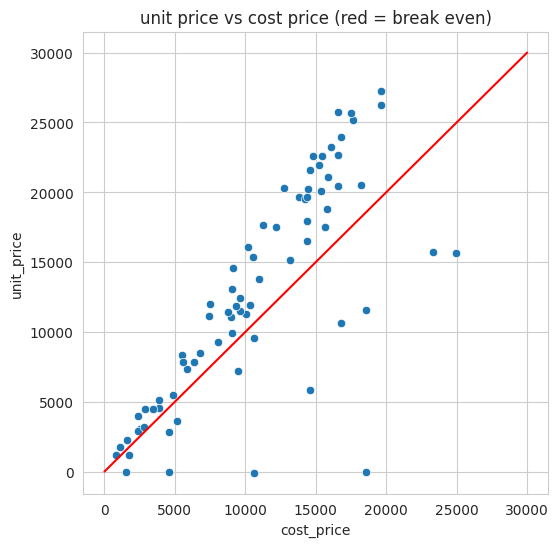

In [12]:
plt.figure(figsize=(6, 6))
sns.scatterplot(data=df, x='cost_price', y='unit_price')
plt.plot([0, 30000], [0, 30000], color='red')
plt.title('unit price vs cost price (red = break even)')
plt.show()

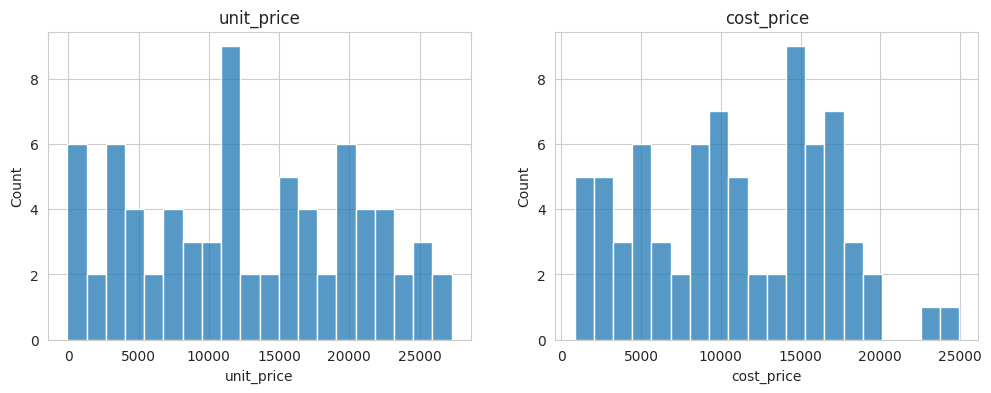

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df['unit_price'], bins=20, ax=ax[0])
sns.histplot(df['cost_price'], bins=20, ax=ax[1])
ax[0].set_title('unit_price')
ax[1].set_title('cost_price')
plt.show()

In [14]:
def parse_date(x):
    if pd.isna(x):
        return pd.NaT
    x = str(x).strip()
    if x == '' or x.lower() == 'unknown':
        return pd.NaT
    if '/' in x:
        a, b, c = [int(i) for i in x.split('/')]
        if a > 12:
            return pd.Timestamp(year=c, month=b, day=a)
        if b > 12:
            return pd.Timestamp(year=c, month=a, day=b)
        return pd.Timestamp(year=c, month=b, day=a)
    if len(x) == 10 and x[4] == '-':
        return pd.to_datetime(x, format='%Y-%m-%d')
    return pd.to_datetime(x, format='%d-%b-%Y')


def is_ambiguous(x):
    if pd.isna(x) or '/' not in str(x):
        return False
    a, b, c = [int(i) for i in str(x).split('/')]
    return a <= 12 and b <= 12 and a != b

In [15]:
before = len(df)
text_cols = df.select_dtypes(exclude='number').columns
for col in text_cols:
    df[col] = df[col].str.strip()
df = df.replace('', np.nan)
df.isnull().sum()

product_id      0
product_name    2
category        5
sub_category    0
unit_price      0
cost_price      0
supplier_id     0
is_active       0
launch_date     0
dtype: int64

In [16]:
df['is_revised'] = df['product_name'].str.contains('Revised', na=False)
df = df.sort_values(['product_id', 'is_revised'], ascending=[True, False])
df = df.drop_duplicates('product_id', keep='first').reset_index(drop=True)
df['product_name'] = df['product_name'].str.replace(' (Revised)', '', regex=False)
df = df.drop(columns='is_revised')
print(before, '->', len(df))
df['product_id'].duplicated().sum()

75 -> 70


np.int64(0)

In [17]:
cat_map = {'electronics': 'Electronics', 'electornics': 'Electronics',
           'home & kitchen': 'Home & Kitchen', 'home and kitchen': 'Home & Kitchen',
           'fashion': 'Fashion', 'grocery': 'Grocery', 'sports': 'Sports'}
df['category'] = df['category'].str.lower().map(cat_map)
df['category'].value_counts(dropna=False)

category
Grocery           17
Fashion           16
Home & Kitchen    15
Sports             9
Electronics        8
NaN                5
Name: count, dtype: int64

In [18]:
df.dropna(subset=['category']).groupby('sub_category')['category'].nunique().max()

np.int64(1)

In [19]:
sub_to_cat = df.dropna(subset=['category']).groupby('sub_category')['category'].agg(lambda s: s.mode()[0])
df['category'] = df['category'].fillna(df['sub_category'].map(sub_to_cat))
df['category'].isnull().sum()

np.int64(0)

In [20]:
expected_name = df['sub_category'] + ' Item ' + df['product_id'].str[1:].astype(int).astype(str)
match = (df['product_name'] == expected_name)[df['product_name'].notna()]
print(match.mean())
df[df['product_name'].isnull()][['product_id', 'sub_category']]

1.0


,product_id,sub_category
7,P008,Menswear
58,P059,Cookware


In [21]:
df['product_name'] = df['product_name'].fillna(expected_name)
df['product_name'].isnull().sum()

np.int64(0)

In [22]:
bool_map = {'y': True, 'yes': True, 'true': True, '1': True,
            'n': False, 'no': False, 'false': False, '0': False}
df['is_active'] = df['is_active'].astype(str).str.lower().map(bool_map)
print(df['is_active'].isnull().sum())
df['is_active'].value_counts()

0


is_active
True     63
False     7
Name: count, dtype: int64

In [23]:
df['launch_ambiguous'] = df['launch_date'].apply(is_ambiguous)
df['launch_date'] = df['launch_date'].apply(parse_date)
print(df['launch_ambiguous'].sum())
df['launch_date'].describe()

9


count                            70
mean     2021-12-31 02:03:25.714285
min             2019-01-01 00:00:00
25%             2020-06-30 12:00:00
50%             2021-10-21 00:00:00
75%             2023-06-25 18:00:00
max             2025-05-24 00:00:00
Name: launch_date, dtype: object

In [24]:
df.loc[df['unit_price'] <= 0, ['product_id', 'unit_price']]

,product_id,unit_price
39,P040,0.0
50,P051,0.0


In [25]:
df.loc[df['unit_price'] <= 0, 'unit_price'] = np.nan
df['unit_price'].isnull().sum()

np.int64(2)

In [26]:
suppliers = pd.read_csv('suppliers_clean.csv')
df['supplier_orphan'] = ~df['supplier_id'].isin(suppliers['supplier_id'])
print(df['supplier_orphan'].sum())
df[df['supplier_orphan']][['product_id', 'supplier_id']]

4


,product_id,supplier_id
15,P016,S98
22,P023,S92
44,P045,S96
68,P069,S93


In [27]:
df['below_cost'] = df['unit_price'] < df['cost_price']
df['margin_pct'] = ((df['unit_price'] - df['cost_price']) / df['unit_price'] * 100).round(2)
print(df['below_cost'].sum())
df[df['below_cost']][['product_id', 'product_name', 'unit_price', 'cost_price', 'margin_pct']]

10


,product_id,product_name,unit_price,cost_price,margin_pct
0,P001,Accessories Item 1,10660.79,16799.61,-57.58
2,P003,Staples Item 3,9543.98,10602.65,-11.09
5,P006,Furniture Item 6,2863.09,4549.93,-58.92
9,P010,Accessories Item 10,1165.83,1730.66,-48.45
12,P013,Appliances Item 13,15622.68,24940.49,-59.64
19,P020,Beverages Item 20,3634.57,5171.78,-42.29
27,P028,Appliances Item 28,7218.53,9457.58,-31.02
38,P039,Fitness Item 39,5818.64,14577.41,-150.53
59,P060,Staples Item 60,11569.57,18576.25,-60.56
64,P065,Footwear Item 65,15706.03,23290.69,-48.29


In [28]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 70 entries, 0 to 69
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   product_id        70 non-null     str           
 1   product_name      70 non-null     str           
 2   category          70 non-null     str           
 3   sub_category      70 non-null     str           
 4   unit_price        68 non-null     float64       
 5   cost_price        70 non-null     float64       
 6   supplier_id       70 non-null     str           
 7   is_active         70 non-null     bool          
 8   launch_date       70 non-null     datetime64[us]
 9   launch_ambiguous  70 non-null     bool          
 10  supplier_orphan   70 non-null     bool          
 11  below_cost        70 non-null     bool          
 12  margin_pct        68 non-null     float64       
dtypes: bool(4), datetime64[us](1), float64(3), str(5)
memory usage: 5.3 KB


In [29]:
df.isnull().sum()

product_id          0
product_name        0
category            0
sub_category        0
unit_price          2
cost_price          0
supplier_id         0
is_active           0
launch_date         0
launch_ambiguous    0
supplier_orphan     0
below_cost          0
margin_pct          2
dtype: int64

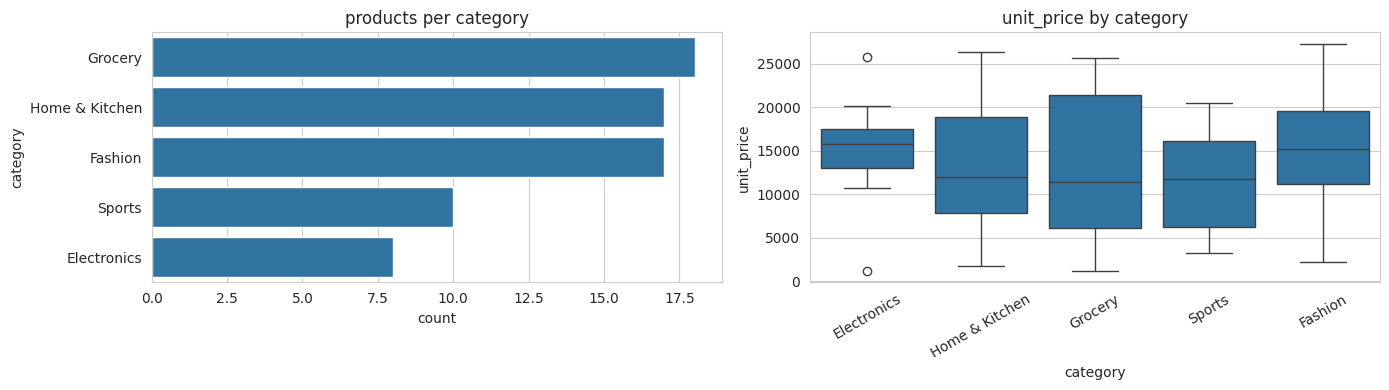

In [30]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
sns.countplot(data=df, y='category', order=df['category'].value_counts().index, ax=ax[0])
sns.boxplot(data=df, x='category', y='unit_price', ax=ax[1])
ax[1].tick_params(axis='x', rotation=30)
ax[0].set_title('products per category')
ax[1].set_title('unit_price by category')
plt.tight_layout()
plt.show()

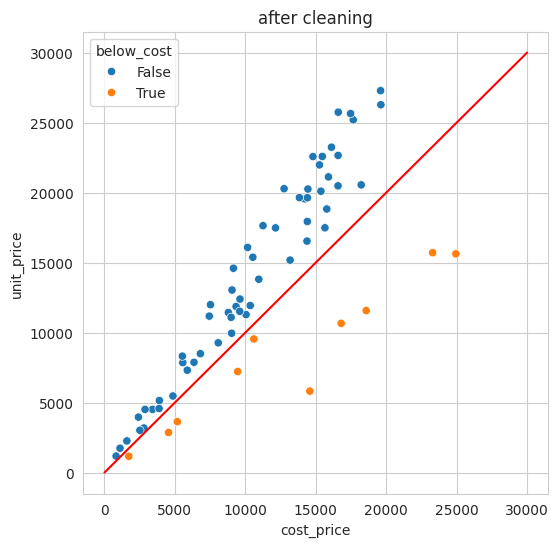

In [31]:
plt.figure(figsize=(6, 6))
sns.scatterplot(data=df, x='cost_price', y='unit_price', hue='below_cost')
plt.plot([0, 30000], [0, 30000], color='red')
plt.title('after cleaning')
plt.show()

In [32]:
df.groupby('category')[['unit_price', 'cost_price', 'margin_pct']].mean().round(2)

,unit_price,cost_price,margin_pct
category,,,
Electronics,14935.08,12063.28,6.90
Fashion,14627.33,10391.70,22.34
Grocery,13052.85,10540.60,13.13
Home & Kitchen,12804.79,10950.20,12.13
Sports,11438.80,9743.39,4.34


In [33]:
df.to_csv('products_clean.csv', index=False)
df.head()

,product_id,product_name,category,sub_category,unit_price,cost_price,supplier_id,is_active,launch_date,launch_ambiguous,supplier_orphan,below_cost,margin_pct
0,P001,Accessories Item 1,Electronics,Accessories,10660.79,16799.61,S014,True,2023-05-31,False,False,True,-57.58
1,P002,Furniture Item 2,Home & Kitchen,Furniture,9953.59,9027.17,S007,False,2021-10-01,True,False,False,9.31
2,P003,Staples Item 3,Grocery,Staples,9543.98,10602.65,S006,True,2021-04-28,False,False,True,-11.09
3,P004,Appliances Item 4,Home & Kitchen,Appliances,21122.18,15898.59,S015,True,2019-12-29,False,False,False,24.73
4,P005,Staples Item 5,Grocery,Staples,17935.95,14399.03,S005,True,2023-03-07,True,False,False,19.72
